   # Titanic EDA
   **Data source:** https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv (via `sns.load_dataset('titanic')`)
   **Extraction date:** 14 October 2026

In [1]:
!pip install -U seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
  Attempting uninstall: seaborn
    Found existing installation: seaborn 0.11.0
    Uninstalling seaborn-0.11.0:
      Successfully uninstalled seaborn-0.11.0


In [2]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
df = sns.load_dataset('titanic')
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()
df.isna().sum()      # أي أعمدة فيها نقص؟
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Data Cleaning
- **age:** 177 missing values filled with the median age by sex and class,
  to keep the distribution realistic.
- **deck:** dropped, since ~77% of values were missing.
- **embarked:** 2 missing values filled with the most common port.

## Feature Engineering
- `family_size = sibsp + parch + 1`
- `is_alone`: 1 if travelling alone
- `age_group`: age bins (Child, Teen, ...)

In [4]:
print(df.isna().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [5]:
# نشتغل على نسخة عشان نحافظ على الأصل
clean = df.copy()

# 1) العمر: نملّيه بوسيط العمر حسب الجنس والدرجة
clean['age'] = clean['age'].fillna(
    clean.groupby(['sex', 'pclass'])['age'].transform('median')
)

# 2) deck: ناقص حوالي 77%، فنشيل العمود
clean = clean.drop(columns=['deck'])

# 3) embarked و embark_town: صفين بس، نملّيهم بالقيمة الأكثر تكرارًا
clean['embarked'] = clean['embarked'].fillna(clean['embarked'].mode()[0])
clean['embark_town'] = clean['embark_town'].fillna(clean['embark_town'].mode()[0])

print(clean.isna().sum())     # المفروض يبقى 0 في كل حاجة مهمة

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [6]:
clean['family_size'] = clean['sibsp'] + clean['parch'] + 1
clean['is_alone'] = (clean['family_size'] == 1).astype(int)
clean['age_group'] = pd.cut(
    clean['age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']
)

In [7]:
clean.to_csv('titanic_cleaned.csv', index=False)

In [8]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs('charts', exist_ok=True)
sns.set_theme(style='whitegrid')

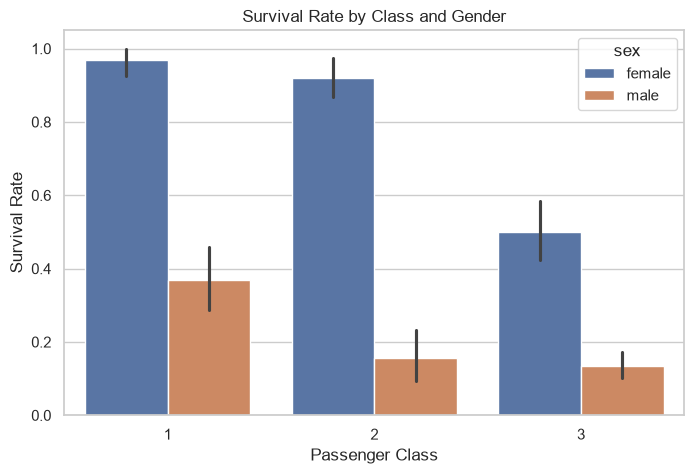

In [9]:
plt.figure(figsize=(8, 5))
sns.barplot(x='pclass', y='survived', hue='sex', data=clean)
plt.title('Survival Rate by Class and Gender')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.savefig('charts/survival_by_class_gender.png', bbox_inches='tight', dpi=150)
plt.show()

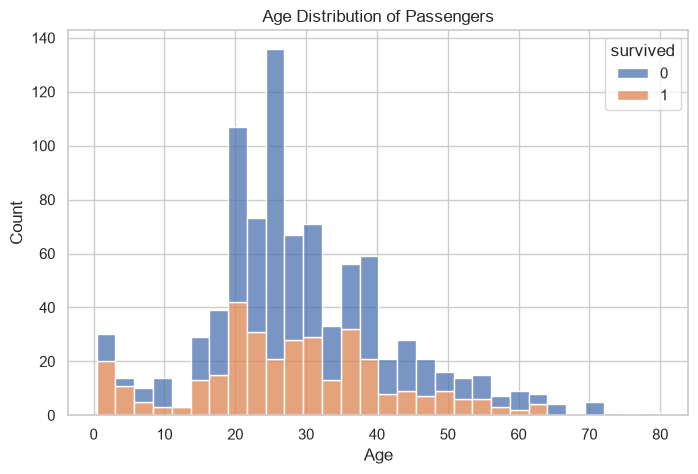

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(data=clean, x='age', bins=30, hue='survived', multiple='stack')
plt.title('Age Distribution of Passengers')
plt.xlabel('Age')
plt.savefig('charts/age_distribution.png', bbox_inches='tight', dpi=150)
plt.show()

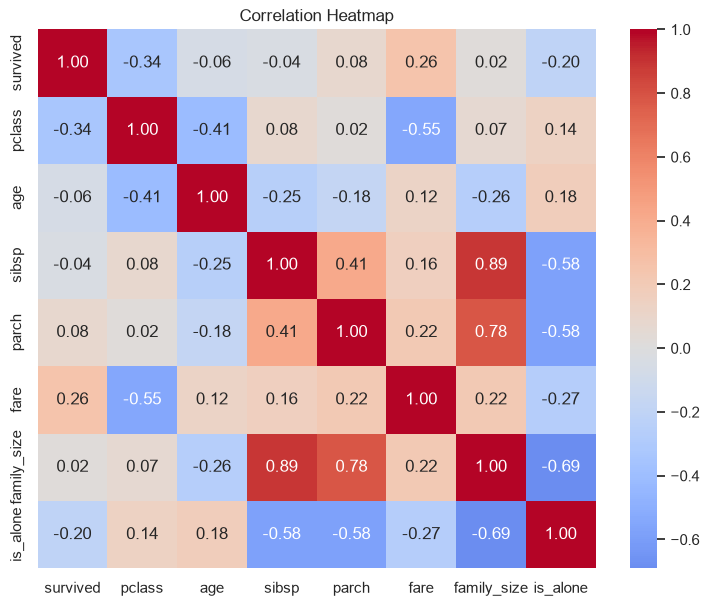

In [11]:
cols = ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone']

plt.figure(figsize=(9, 7))
sns.heatmap(clean[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.savefig('charts/correlation_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()

In [12]:
print(clean.groupby('sex')['survived'].mean().round(3))
print(clean.groupby('pclass')['survived'].mean().round(3))
print(clean.groupby(['pclass','sex'])['survived'].mean().round(3))
print(clean.groupby('age_group', observed=True)['survived'].mean().round(3))
print(clean.groupby('is_alone')['survived'].mean().round(3))
print(clean[cols].corr()['survived'].round(2))

sex
female    0.742
male      0.189
Name: survived, dtype: float64
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64
pclass  sex   
1       female    0.968
        male      0.369
2       female    0.921
        male      0.157
3       female    0.500
        male      0.135
Name: survived, dtype: float64
age_group
Child          0.580
Teen           0.429
Young Adult    0.358
Adult          0.384
Senior         0.227
Name: survived, dtype: float64
is_alone
0    0.506
1    0.304
Name: survived, dtype: float64
survived       1.00
pclass        -0.34
age           -0.06
sibsp         -0.04
parch          0.08
fare           0.26
family_size    0.02
is_alone      -0.20
Name: survived, dtype: float64


## Key Observations

1. **Gender was the strongest factor.** Women survived at 74.2% versus 18.9% for men.
   Within each class women survived far more often (96.8% in 1st class vs 50.0% in 3rd).
2. **Class mattered a lot.** Survival fell from 63.0% (1st) to 47.3% (2nd) to 24.2% (3rd),
   consistent with the correlation of -0.34 between class and survival.
   Third-class men were hit hardest, with only 13.5% surviving.
3. **Children and small families had better odds.** Children (≤12) survived at 58.0%,
   and passengers travelling with family survived at 50.6% versus 30.4% for solo travellers.
   Very large families (5+ members) did poorly.
4. **Higher fares correlate with survival** (+0.26), reflecting that fare is tied to class.

## Conclusion
Survival on the Titanic was strongly shaped by gender, class and family situation.
"Women and children first" is visible in the data (women 74%, children 58%), but class
created a large gap even among women. Passengers who paid higher fares in 1st class had
the best odds, while solo male travellers in 3rd class had the worst.
Missing ages were imputed using the median by sex and class (≈20% of rows), so age-based
findings are approximate.